In [2]:
import numpy as np, math
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

import matplotlib.pyplot as plt
from scipy.optimize import brentq

In [3]:
# Constants
G=6.674e-11 
mE=5.972e24
mM=7.348e22
d=3.844e8

In [4]:
# System paramters and basic motion


w =math.sqrt(G*(mE+mM)/d**3) # angular velocity of the system
T = 2*math.pi/w # period of the system

rE= mM*d/(mE+mM) # distance of earth from barycentre
rM= mE*d/(mE+mM) # distance of moon from barycentre


def body_pos(t): 
    cos_comp ,sine_comp = np.cos(w*t), np.sin(w*t)
    return ((-mM*d/(mE+mM)*cos_comp, -mM*d/(mE+mM)*sine_comp), (mE*d/(mE+mM)*cos_comp, mE*d/(mE+mM)*sine_comp))

def body_vel(t):
    cos_comp ,sine_comp = np.cos(w*t), np.sin(w*t)
    return ((mM*d/(mE+mM)*w*sine_comp, -mM*d/(mE+mM)*w*cos_comp), (-mE*d/(mE+mM)*w*sine_comp, mE*d/(mE+mM)*w*cos_comp))

def initial_conditions_planests(t0):                         # gives positon and velocity of each body at the start
    pos = body_pos(t0)
    vel = body_vel(t0)
    return (pos[0][0], pos[0][1], pos[1][0], pos[1][1],
            vel[0][0], vel[0][1], vel[1][0], vel[1][1])

def init(dr,t):                                                 #initial position of satellite dr past the moon at a time t 
    cos_comp ,sine_comp = np.cos(w*t), np.sin(w*t)
    return ((rM+dr)*cos_comp, (rM+dr)*sine_comp, 
            -w*(rM+dr)*sine_comp, w*(rM+dr)*cos_comp)

def func_to_solve(t, s):
    x, y, vx, vy = s             
    (xE, yE),(xM, yM) = body_pos(t)
    dEx,dEy,dMx,dMy=x-xE,y-yE,x-xM,y-yM
    dE3=(dEx*dEx+dEy*dEy)**1.5; dM3=(dMx*dMx+dMy*dMy)**1.5
    return np.array([vx, vy , -G*mE*dEx/dE3 - G*mM*dMx/dM3, -G*mE*dEy/dE3 - G*mM*dMy/dM3])


In [5]:
#Scipy Solver 
def Scipy_solver(func,t_span, s, t_eval):
    sol = solve_ivp(func, t_span, s , t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
    return sol 

#Scipy Solver with dense output  - FIX COS TS BROKEN
def Scipy_solver_dense(func, T0, T, n, dr):
    s = init(dr, T0)
    t = np.linspace(T0, T, n)
    sol = solve_ivp(func, [T0, T], s,t_eval=t,method='RK45',rtol=1e-9,atol=1e-9,dense_output=True)
    return sol


In [45]:
#Taylor Solver -ADD JERK LATER - THINK ABOUT HOW I STORE THE DATA IM USING AND WHAT TIMESTEP PARAMETRS TO USE
def Taylor_solver(dr , T0, T,h=10.0 , store = 200):
    
    N=int(round((T-T0)/h))
    h=(T-T0)/N

    x,y,vx,vy = init(dr,T0)    
    out = []

    times = np.array([T0])
    for i in  range(N+1):
        t=T0+i*h
        
        
        if i % store ==0 or i == N:
            out.append((t,x,y,vx,vy))

        if i == N:
            break
        
        acc = func_to_solve(t, [x, y, vx, vy])
        new_X = x + h*vx + 0.5*h*h*acc[2]
        new_y = y + h*vy + 0.5*h*h*acc[3]
        new_vx = vx + h*acc[2]
        new_vy = vy + h*acc[3]

        x,y,vx,vy = new_X, new_y, new_vx , new_vy

    pos = (np.array(out).T)[0:2]
    time = (np.array(out).T)[0]  
    return pos,time


In [46]:
pos, time = Taylor_solver( 6e6 , 0, T=T,h=10.0 , store = 200)

print(pos)
print(type(pos))
print(pos.shape)

print(time)
print(type(time))
print(time.shape)


[[0.00000000e+00 2.00000123e+03 4.00000245e+03 ... 2.35400144e+06
  2.35600145e+06 2.35747145e+06]
 [3.85727797e+08 3.85445898e+08 3.84540931e+08 ... 9.37947361e+08
  9.38805957e+08 9.39437020e+08]]
<class 'numpy.ndarray'>
(2, 1180)
[0.00000000e+00 2.00000123e+03 4.00000245e+03 ... 2.35400144e+06
 2.35600145e+06 2.35747145e+06]
<class 'numpy.ndarray'>
(1180,)


In [28]:
#Runga Kutta Solver- need to make quikcer usign the better append method 
def rk_step(f,t,u,h):
    k1 = f(t,u)
    k2 = f(t + h/2, u + h*k1/2)
    k3 = f(t + h/2, u + h*k2/2) 
    k4 = f(t + h, u + h*k3)
    return u + h*(k1 + 2*k2 + 2*k3 + k4)/6

def Runga_Kutta_solver(f , T0,dr, T_end,h):
    pos = np.array([init(dr, T0)])    
    times = np.array([T0])
    t=T0
    while t<T_end:
        s = rk_step(f,t,pos[-1], h)
        pos = np.append(pos, [s], axis=0)
        t += h
        times = np.append(times, t)
    return times, pos
    

In [47]:
#calling all the solutions- need to decide on the optimal paramters
#Scipy Parameters:
func_scipy=func_to_solve
T0_scipy = 0
T_scipy = T
n_scipy = 100
dr_scipy = 6e6

#Taylor Parameters:
dr_taylor = 6e6
T0_taylor = 0
T_taylor = T
n_taylor = 1000

#Rk parameters:
f = func_to_solve
T0_rk = 0
dr_rk = 6e6
T_end_rk = T
h_rk = 100


pos_taylor, time_taylor = Taylor_solver( 6e6 , 0, T=T,h=10.0 , store = 200)
times_scipy = (Scipy_solver_dense(func_scipy, T0_scipy, T_scipy, n_scipy, dr_scipy)).t
pos_scipy = (Scipy_solver_dense(func_scipy, T0_scipy, T_scipy, n_scipy, dr_scipy)).y
times_rk , pos_rk = Runga_Kutta_solver(f , T0_rk,dr_rk, T_end_rk,h_rk)

# moon and earth position sover same interval
t_bodies = np.linspace(0, T, 1000)
moon_pos = np.array([body_pos(t_bodies)[1]])
earth_pos = np.array([body_pos(t_bodies)[0]])

In [48]:
# moon and earth positions over same interval
t_bodies = np.linspace(0, T, 1000)
moon_pos = np.array([body_pos(t_bodies)[1]])
earth_pos = np.array([body_pos(t_bodies)[0]])

In [49]:
print(moon_pos)

[[[ 3.79727797e+08  3.79720286e+08  3.79697755e+08 ...  3.79697755e+08
    3.79720286e+08  3.79727797e+08]
  [ 0.00000000e+00  2.38827266e+06  4.77645084e+06 ... -4.77645084e+06
   -2.38827266e+06 -9.30064861e-08]]]


C:\Users\thoma\AppData\Local\Temp\ipykernel_12760\2350962094.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


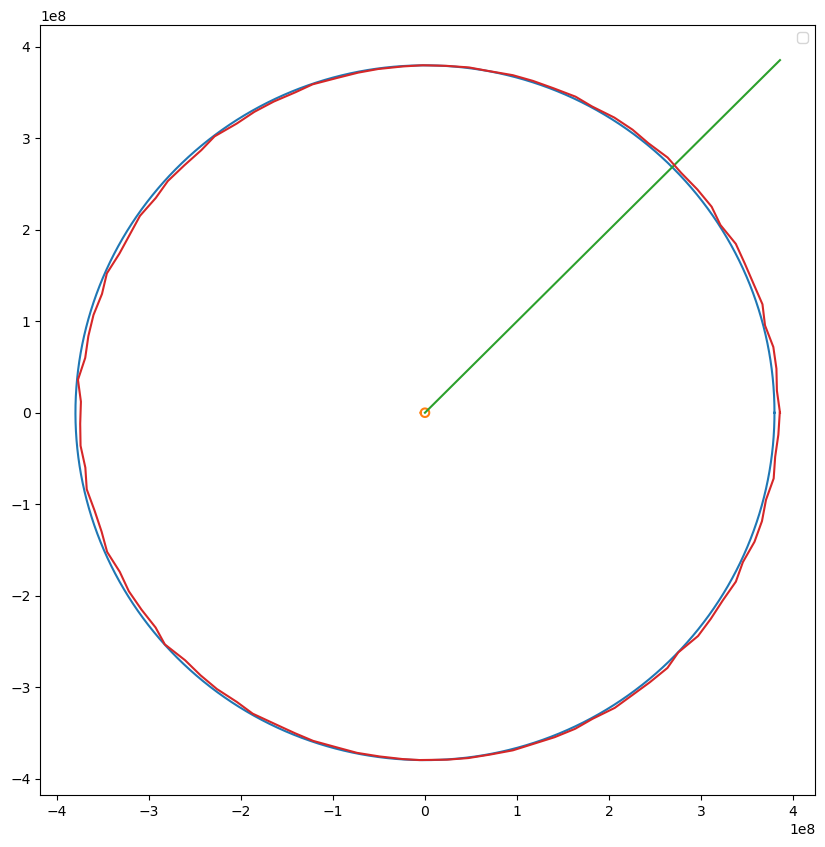

In [51]:
#plots for each 
fig, ax = plt.subplots(figsize=(10, 10))

ax.plot(moon_pos[0,0], moon_pos[0,1])
ax.plot(earth_pos[0,0], earth_pos[0,1])
ax.plot(pos_taylor[:,0], pos_taylor[:,1])
ax.plot(pos_scipy[0,:], pos_scipy[1,:])
#ax.plot(pos_rk[:,0], pos_rk[:,1])

ax.legend()

plt.show()